# INT4096 — Machine Learning: Supervised Learning
## Integrated Google Colab Demonstration

- student-support **classification** using **Logistics Regression**;
- **Decision Tree** and **K-Nearest Neighbours (KNN)**;
- **generalisation**, overfitting and model selection;


> **Teaching note:** The records are synthetic. They are suitable for learning Python and machine-learning workflows, but not for making decisions about real students.

## Learning outcomes

After completing the notebook, students should be able to:

1. distinguish classification from regression;
2. separate features `X` from a target `y`;
3. split data into training and test sets;
4. train and evaluate Decision Tree, KNN and regression models;
5. explain why KNN and regularized regression require feature scaling;
6. identify overfitting by comparing training and test performance; and
7. interpret model output as evidence for human review rather than an automatic judgement.

## 1. Import the required libraries

In [ ]:
# Colab already includes pandas, NumPy, matplotlib and scikit-learn.
# Therefore, no installation command is normally required.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# Make the printed tables easier to read.
pd.set_option("display.max_columns", None)
np.set_printoptions(precision=3, suppress=True)

## 2. Load the dataset

The code below creates synthetic records for 500 students. The dataset contains:

- `student_id`: identifier only — **never use it as a predictive feature**;
- `attendance`: attendance percentage;
- `previous_score`: score from an earlier assessment;
- `study_hours`: weekly study time;
- `lms_clicks`: activity in the learning-management system;
- `assignment_completion`: percentage of assignments completed;
- `needs_support`: classification target (`Yes` or `No`); and
- `final_score`: regression target (a continuous number).

The fixed random seed makes the same dataset appear every time the notebook runs.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Student-Support Classification

**Question:** Which students may need additional learning support?

- **Features `X`:** attendance, previous score, study hours and LMS clicks
- **Target `y`:** `needs_support` (`Yes` or `No`)


In [ ]:
students = pd.read_csv('/content/sample_data/student_data_support.csv')

# 3. Inspect the dataset before modelling

In [ ]:

print("Rows, columns:", students.shape)
print (students.info())
display(students.head())
print("\nMissing values per column:")
display(students.isna().sum().to_frame("missing_values"))
display(students.describe())
classification_features = [
    "attendance",
    "previous_score",
    "study_hours",
    "lms_clicks",
    "assignment_completion"

]

X_cls = students[classification_features]
y_cls = students["needs_support"]

# Split before fitting any preprocessing or model.
# stratify=y_cls keeps a similar Yes/No proportion in both subsets.
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.25,
    stratify=y_cls,
    random_state=42,
)
print("Traning data:", X_train_cls.shape)
print("Test data:", X_test_cls.shape)
print("Training target proportions:")
display(y_train_cls.value_counts(normalize=True).round(3))

Rows, columns: (500, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   student_id             500 non-null    object 
 1   attendance             500 non-null    float64
 2   previous_score         500 non-null    float64
 3   study_hours            500 non-null    float64
 4   lms_clicks             500 non-null    int64  
 5   assignment_completion  500 non-null    float64
 6   needs_support          500 non-null    object 
 7   final_score            500 non-null    float64
dtypes: float64(5), int64(1), object(2)
memory usage: 31.4+ KB
None


,student_id,attendance,previous_score,study_hours,lms_clicks,assignment_completion,needs_support,final_score
0,S0001,81.7,87.1,4.9,33,75.2,No,74.6
1,S0002,65.5,80.5,3.4,31,72.0,Yes,65.0
2,S0003,87.0,57.9,4.1,74,88.5,Yes,68.3
3,S0004,89.3,47.0,6.4,52,85.8,No,63.2
4,S0005,54.6,26.5,5.0,40,60.9,Yes,45.5



Missing values per column:


,missing_values
student_id,0
attendance,0
previous_score,0
study_hours,0
lms_clicks,0
assignment_completion,0
needs_support,0
final_score,0


,attendance,previous_score,study_hours,lms_clicks,assignment_completion,final_score
count,500.000000,500.00000,500.000000,500.000000,500.000000,500.000000
mean,77.700200,67.35300,5.001200,41.744000,81.084200,64.717800
std,11.188189,14.10232,2.217113,21.591917,13.693888,8.780778
min,47.200000,25.00000,0.000000,0.000000,36.000000,39.400000
25%,69.975000,57.82500,3.500000,27.750000,71.575000,58.900000
50%,78.050000,68.15000,5.000000,42.000000,82.550000,65.000000
75%,85.025000,76.37500,6.400000,56.000000,91.900000,70.600000
max,100.000000,100.00000,11.200000,109.000000,100.000000,95.500000


Traning data: (375, 5)
Test data: (125, 5)
Training target proportions:


,proportion
needs_support,
No,0.661
Yes,0.339


In [ ]:

#1 Import required external libraries
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler


# 2. Define the features and target for classification
classification_features = ["attendance", "previous_score", "study_hours", "lms_clicks"]
X_cls = students[classification_features]
y_cls = students["needs_support"]


# 3 Split before fitting any preprocessing or model.
# stratify=y_cls keeps a similar Yes/No proportion in both subsets.
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.25,
    stratify=y_cls,
    random_state=42,
)
#4.  Scale the data before fitting into model
scaler = StandardScaler()

# Fit on training data and transform both training and test sets
X_train_scaled = scaler.fit_transform(X_train_cls)
X_test_scaled = scaler.transform(X_test_cls)


#5 Initialize and fit the Logistic Regression model
logistic_model = LogisticRegression(random_state=42)

#6 Train the model on the scaled training features
logistic_model.fit(X_train_scaled, y_train_cls)


#7 Test the performance of your model
train_accuracy = logistic_model.score(X_train_scaled, y_train_cls)
test_accuracy = logistic_model.score(X_test_scaled, y_test_cls)

print(f"Training Accuracy: {train_accuracy:.3f}")
print(f"Test Accuracy:     {test_accuracy:.3f}")


# 3. Create a DataFrame for a new student (feature names and order must match X_cls)
new_student_cls = pd.DataFrame([{
    "attendance": 69,
    "previous_score": 54,
    "study_hours": 8,
    "lms_clicks": 13,
}])

# Scale the new student data using the already fitted scaler
new_student_scaled = scaler.transform(new_student_cls)

# Predict the class label and probabilities
prediction = logistic_model.predict(new_student_scaled)[0]
prediction_proba = logistic_model.predict_proba(new_student_scaled)[0]


# Display results
print("Logistic Regression Prediction:", prediction)
print(f"Probabilities — No: {prediction_proba[0]:.3f}, Yes: {prediction_proba[1]:.3f}")

Training Accuracy: 0.827
Test Accuracy:     0.768
Logistic Regression Prediction: No
Probabilities — No: 0.506, Yes: 0.494


# Making use of Pipeline object to streamline the data processing steps

In [ ]:

#1  Import required library
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# 2. Define the features and target for classification
classification_features = ["attendance", "previous_score", "study_hours", "lms_clicks"]
X_cls = students[classification_features]
y_cls = students["needs_support"]


# 3 Split before fitting any preprocessing or model.
# stratify=y_cls keeps a similar Yes/No proportion in both subsets.
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.25,
    stratify=y_cls,
    random_state=42,
)
#4. Build and train the Logistic Regression pipeline
logistic_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(random_state=42))
])

#5 Train on the training data (X_train_cls, y_train_cls)
logistic_pipeline.fit(X_train_cls, y_train_cls)

#6 Calculate accuracy directly using the pipeline
train_acc = logistic_pipeline.score(X_train_cls, y_train_cls)
test_acc = logistic_pipeline.score(X_test_cls, y_test_cls)

#7 Create a DataFrame for a new student (feature names and order must match X_cls)
new_student_cls = pd.DataFrame([{
    "attendance": 69,
    "previous_score": 54,
    "study_hours": 8,
    "lms_clicks": 13,
}])

# 8 Predict the class label and probability
prediction = logistic_pipeline.predict(new_student_cls)[0]
prediction_proba = logistic_pipeline.predict_proba(new_student_cls)[0]

# 9 Display results
print(f"Training Accuracy: {train_acc:.3f}")
print(f"Test Accuracy:     {test_acc:.3f}")
print("Logistic Regression Prediction:", prediction)
print(f"Probabilities — No: {prediction_proba[0]:.3f}, Yes: {prediction_proba[1]:.3f}")

Training Accuracy: 0.827
Test Accuracy:     0.768
Logistic Regression Prediction: No
Probabilities — No: 0.506, Yes: 0.494


In [ ]:
# Begin with a small, interpretable tree.
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train_cls, y_train_cls)

tree_train_pred = tree_model.predict(X_train_cls)
tree_test_pred = tree_model.predict(X_test_cls)

tree_train_accuracy = accuracy_score(y_train_cls, tree_train_pred)
tree_test_accuracy = accuracy_score(y_test_cls, tree_test_pred)

print(f"Decision Tree training accuracy: {tree_train_accuracy:.3f}")
print(f"Decision Tree test accuracy:     {tree_test_accuracy:.3f}")
print("\nDetailed test-set results:")
print(classification_report(y_test_cls, tree_test_pred))

Decision Tree training accuracy: 0.856
Decision Tree test accuracy:     0.768

Detailed test-set results:
              precision    recall  f1-score   support

          No       0.83      0.82      0.82        83
         Yes       0.65      0.67      0.66        42

    accuracy                           0.77       125
   macro avg       0.74      0.74      0.74       125
weighted avg       0.77      0.77      0.77       125



# Multi-Class Classification with Logistics Regression

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Load the dataset
# Adjust path if student_data2.csv is uploaded in Colab session storage
students = pd.read_csv("/content/sample_data/student_data2.csv")

# 2. Define features (X) and target (y)
classification_features = [
    "attendance",
    "previous_score",
    "study_hours",
    "lms_clicks",
]
X_cls = students[classification_features]
y_cls = students["dropout_risk"]  # Target with classes: 'High', 'Medium', 'Low'

# 3. Split into training and testing sets (using stratify to preserve class proportions)
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.25, stratify=y_cls, random_state=42
)

# 4. Build a pipeline with StandardScaler and Multinomial Logistic Regression
logistic_pipeline = Pipeline(
    [
        ("scaler", StandardScaler()),
        (
            "model",
            LogisticRegression(
                multi_class="multinomial", solver="lbfgs", random_state=42
            ),
        ),
    ]
)

# 5. Train the model
logistic_pipeline.fit(X_train_cls, y_train_cls)

# 6. Evaluate the model performance on the test set
y_train_pred = logistic_pipeline.predict(X_train_cls)
y_test_pred = logistic_pipeline.predict(X_test_cls)

print(f"Training Accuracy: {accuracy_score(y_train_cls, y_train_pred):.3f}")
print(f"Test Accuracy: {accuracy_score(y_test_cls, y_test_pred):.3f}\n")
print("Detailed Classification Report:")
print(classification_report(y_test_cls, y_test_pred))

# 7. Predict dropout risk and class probabilities for a new student case
new_student = pd.DataFrame(
    [
        {
            "attendance": 65,
            "previous_score": 48,
            "study_hours": 3,
            "lms_clicks": 10,
        }
    ]
)

predicted_risk = logistic_pipeline.predict(new_student)[0]
predicted_probs = logistic_pipeline.predict_proba(new_student)[0]
class_names = logistic_pipeline.classes_  # Array of class labels

print("--- Prediction for New Student ---")
print("Predicted Dropout Risk:", predicted_risk)
print("Class Probabilities:")
for cls_name, prob in zip(class_names, predicted_probs):
  print(f"  {cls_name}: {prob:.3f}")

FileNotFoundError: [Errno 2] No such file or directory: '/content/sample_data/student_data2.csv'

## 3. Decision Tree classification

A Decision Tree learns a sequence of if–then rules. `max_depth` limits the number of levels and helps control overfitting. Feature scaling is generally unnecessary because a tree compares one feature with a threshold at each split.

In [ ]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier

students = pd.DataFrame({
    "attendance": [92, 85, 78, 76, 74, 70, 68, 60, 82, 88, 80, 77],
    "previous_score": [78, 72, 60, 68, 75, 65, 55, 80, 62, 90, 70, 66],
    "needs_support": ["No", "No", "Yes", "No", "Yes", "Yes",
                      "Yes", "Yes", "Yes", "No", "No", "No"]
})

X = students[["attendance", "previous_score"]]
y = students["needs_support"]

# Split dataset into Training (80%) and Testing (20%) sets
# stratify=y preserves the balance of "Yes" and "No" in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
model = DecisionTreeClassifier(max_depth=2, random_state=42)
model.fit(X_train, y_train)

feature = X.columns[model.tree_.feature[0]]
threshold = model.tree_.threshold[0]

print("Selected feature:", feature)
print("Selected threshold:", round(threshold, 2))

Selected feature: previous_score
Selected threshold: 65.5


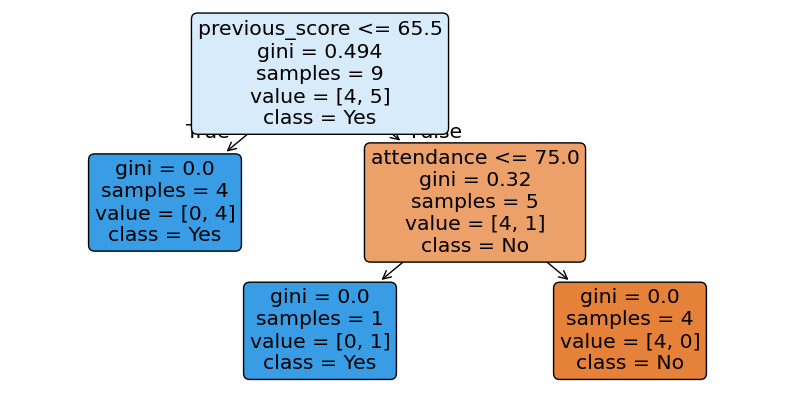

Prediction for the new student: Yes


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

students = pd.DataFrame({
    "attendance": [92, 85, 78, 76, 74, 70, 68, 60, 82, 88, 80, 77],
    "previous_score": [78, 72, 60, 68, 75, 65, 55, 80, 62, 90, 70, 66],
    "needs_support": ["No", "No", "Yes", "No", "Yes", "Yes",
                      "Yes", "Yes", "Yes", "No", "No", "No"]
})

X = students[["previous_score","attendance" ]]
y = students["needs_support"]

# Split dataset into Training (80%) and Testing (20%) sets
# stratify=y preserves the balance of "Yes" and "No" in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = DecisionTreeClassifier(max_depth=2, random_state=42)
model.fit(X_train, y_train)

plt.figure(figsize=(10, 5))
plot_tree(model, feature_names=X.columns,
          class_names=model.classes_,
          filled=True, rounded=True)
plt.show()

# Make a prediction for a new unseen student
new_student =pd.DataFrame({"previous_score": [67],
                           "attendance": [74]
                           })
prediction = model.predict(new_student)[0]
print("Prediction for the new student:", prediction)

#Using Decision Tree to classify students with drop-out risk

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

# ---------------------------------------------------------
# Step 1: Feature & Target Isolation + Stratified Train/Test Split
# ---------------------------------------------------------
# Features (X) and Target (y)
features = ["attendance", "previous_score", "study_hours", "lms_clicks", "assignment_completion"]
X = students[features]
y = students["needs_support"]  # Target indicating risk level

# Stratified split ensures equal class proportion in both subsets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# ---------------------------------------------------------
# Step 2: Logistic Regression (Requires Feature Scaling)
# ---------------------------------------------------------
log_reg_pipeline = Pipeline([
    ("scaler", StandardScaler()),  # Scale features to mean=0, std=1
    ("classifier", LogisticRegression(random_state=42))
])

log_reg_pipeline.fit(X_train, y_train)

log_reg_train_acc = accuracy_score(y_train, log_reg_pipeline.predict(X_train))
log_reg_test_acc  = accuracy_score(y_test, log_reg_pipeline.predict(X_test))

# ---------------------------------------------------------
# Step 3: Decision Tree (Does not require scaling)
# ---------------------------------------------------------
tree_model = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_model.fit(X_train, y_train)

tree_train_acc = accuracy_score(y_train, tree_model.predict(X_train))
tree_test_acc  = accuracy_score(y_test, tree_model.predict(X_test))

# ---------------------------------------------------------
# Step 4: Summary Comparison Table
# ---------------------------------------------------------
results_df = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree (max_depth=3)"],
    "Training Accuracy": [log_reg_train_acc, tree_train_acc],
    "Test Accuracy": [log_reg_test_acc, tree_test_acc],
    "Accuracy Gap (Train - Test)": [
        log_reg_train_acc - log_reg_test_acc,
        tree_train_acc - tree_test_acc
    ]
})

print(results_df.round(3))

                         Model  Training Accuracy  Test Accuracy  \
0          Logistic Regression              0.832          0.752   
1  Decision Tree (max_depth=3)              0.856          0.768   

   Accuracy Gap (Train - Test)  
0                        0.080  
1                        0.088  


### Generalisation: compare tree depths

A model generalises when it performs well on unseen data. A very deep tree can memorize the training set, producing high training accuracy but weaker test performance. We compare several depths using both the held-out test set and five-fold cross-validation on the training set.

5-fold cross-validation is a robust technique used in machine learning to evaluate how well a model generalizes to unseen data without wasting precious training records.

Here is how the process works step-by-step:

**1. The Split **

Imagine you take your entire training dataset and chop it evenly into 5 distinct parts (called folds):

Fold 1, Fold 2, Fold 3, Fold 4, and Fold 5.

**2. The Rotation (Training & Testing 5 Times)**

Instead of training just once, the model goes through 5 iterations (or "rounds"). In each round, a different fold is held out as the validation set, while the remaining 4 folds are combined to train the model:

Round 1: Train on Folds 2, 3, 4, 5 --> Test and score on Fold 1

Round 2: Train on Folds 1, 3, 4, 5 --> Test and score on Fold 2

Round 3: Train on Folds 1, 2, 4, 5 --> Test and score on Fold 3

Round 4: Train on Folds 1, 2, 3, 5 --> Test and score on Fold 4

Round 5: Train on Folds 1, 2, 3, 4 --> Test and score on Fold 5

**3. Averaging the Scores**

At the end of the 5 rounds, you have 5 separate accuracy scores. Cross-validation takes the average of these 5 scores. This final average becomes a much more trustworthy performance metric because every single data point got a turn being part of the validation test.

In [8]:
from sklearn.model_selection import cross_val_score
depth_results = []

for depth in [1, 2, 3, 4, 5, 8, 12, None]:
    candidate = DecisionTreeClassifier(max_depth=depth, random_state=42)
    candidate.fit(X_train_cls, y_train_cls)

    train_acc = candidate.score(X_train_cls, y_train_cls)
    test_acc = candidate.score(X_test_cls, y_test_cls)

    # 1. Compute 5-fold cross-validation and take the mean score
    cv_scores = cross_val_score(candidate, X_train_cls, y_train_cls, cv=5)
    cv_acc = cv_scores.mean()


    depth_results.append({
        "max_depth": "None" if depth is None else str(depth),
        "training_accuracy": train_acc,
        "test_accuracy": test_acc,
        "mean_cv_accuracy": cv_acc,
    })

depth_table = pd.DataFrame(depth_results)
display(depth_table.round(3))

depth_table.plot(
    x="max_depth",
    y=["training_accuracy", "test_accuracy", "mean_cv_accuracy"],
    marker="o",
    figsize=(10, 5),
)
plt.ylim(0.5, 1.02)
plt.ylabel("Accuracy")
plt.title("Model complexity and generalisation")
plt.grid(alpha=0.3)
plt.show()

NameError: name 'DecisionTreeClassifier' is not defined

## 4. K-Nearest Neighbours classification

KNN predicts from the labels of nearby training examples. Because distance is sensitive to numerical units, the features must be scaled. A `Pipeline` ensures that `StandardScaler` learns its mean and standard deviation from training data only.

In [5]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X = pd.DataFrame({
    "attendance": [92, 88, 85, 81, 78, 75, 72, 68, 65, 62],
    "previous_score": [88, 82, 76, 73, 68, 64, 60, 55, 50, 46]
})
y = ["No", "No", "No", "No", "No",
     "Yes", "Yes", "Yes", "Yes", "Yes"]

model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)
model.fit(X, y)

new_student = pd.DataFrame({
    "attendance": [90],
    "previous_score": [58]
})

prediction = model.predict(new_student)[0]
print("Needs support:", prediction)

Needs support: No


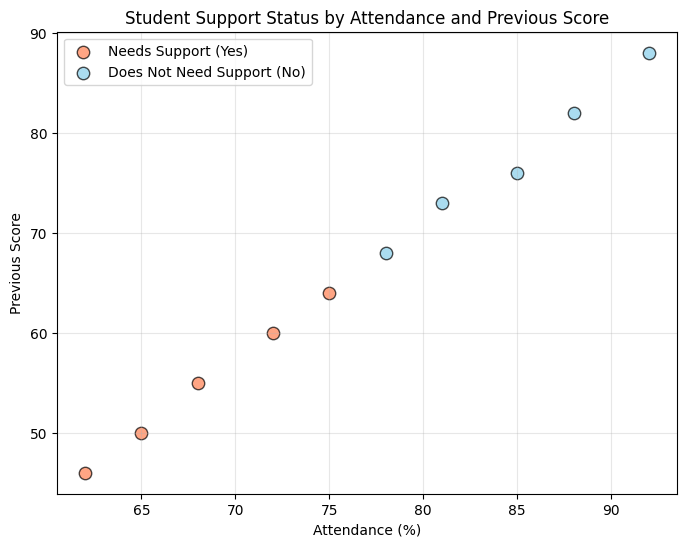

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

# Re-establish the small dataset from cell [2] for plotting
students_plot = pd.DataFrame({
    "attendance": [92, 88, 85, 81, 78, 75, 72, 68, 65, 62],
    "previous_score": [88, 82, 76, 73, 68, 64, 60, 55, 50, 46],
    "needs_support": ["No", "No", "No", "No", "No", "Yes", "Yes", "Yes", "Yes", "Yes"]
})

# Create the figure
plt.figure(figsize=(8, 6))

# Separate the data by the target class ('needs_support')
support_yes = students_plot[students_plot["needs_support"] == "Yes"]
support_no = students_plot[students_plot["needs_support"] == "No"]

# Plot students who DO need support
plt.scatter(
    support_yes["attendance"],
    support_yes["previous_score"],
    color="coral",
    label="Needs Support (Yes)",
    alpha=0.7,
    s=80,
    edgecolors="k"
)

# Plot students who DO NOT need support
plt.scatter(
    support_no["attendance"],
    support_no["previous_score"],
    color="skyblue",
    label="Does Not Need Support (No)",
    alpha=0.7,
    s=80,
    edgecolors="k"
)

# Add labels, title, and legend
plt.xlabel("Attendance (%)")
plt.ylabel("Previous Score")
plt.title("Student Support Status by Attendance and Previous Score")
plt.legend()
plt.grid(alpha=0.3)

# Display the plot
plt.show()

In [ ]:
import pandas as pd
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier

X = pd.DataFrame({
    "attendance": [92, 68, 81, 74, 88, 63, 95, 71, 84, 66],
    "previous_score": [78, 55, 70, 60, 82, 50, 90, 58, 75, 52],
    "lms_clicks": [40, 12, 28, 18, 38, 9, 45, 15, 32, 10]
})
y = ["No", "Yes", "No", "Yes", "No",
     "Yes", "No", "Yes", "No", "Yes"]

model = make_pipeline(
    StandardScaler(),
    KNeighborsClassifier(n_neighbors=3)
)
model.fit(X, y)

new_student = pd.DataFrame({
    "attendance": [70],
    "previous_score": [57],
    "lms_clicks": [14]
})

prediction = model.predict(new_student)[0]
print("Needs support:", prediction)

Needs support: Yes


In [7]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
# Tune k using cross-validation on the training set.
# The pipeline prevents scaling leakage inside every validation fold.
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid={"knn__n_neighbors": list(range(1, 22, 2))},
    scoring="accuracy",
    cv=5,
)
knn_search.fit(X_train_cls, y_train_cls)

best_knn = knn_search.best_estimator_
knn_train_accuracy = best_knn.score(X_train_cls, y_train_cls)
knn_test_accuracy = best_knn.score(X_test_cls, y_test_cls)

print("Best k:", knn_search.best_params_["knn__n_neighbors"])
print(f"Best mean validation accuracy: {knn_search.best_score_:.3f}")
print(f"KNN training accuracy:         {knn_train_accuracy:.3f}")
print(f"KNN test accuracy:             {knn_test_accuracy:.3f}")

NameError: name 'X_train_cls' is not defined

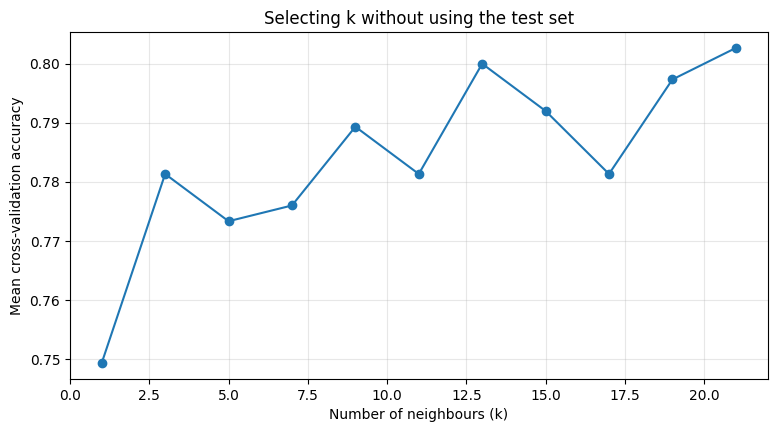

In [ ]:
# Visualize how the choice of k affects validation accuracy.
knn_cv_results = pd.DataFrame(knn_search.cv_results_)

plt.figure(figsize=(9, 4.5))
plt.plot(
    knn_cv_results["param_knn__n_neighbors"].astype(int),
    knn_cv_results["mean_test_score"],
    marker="o",
)
plt.xlabel("Number of neighbours (k)")
plt.ylabel("Mean cross-validation accuracy")
plt.title("Selecting k without using the test set")
plt.grid(alpha=0.3)
plt.show()

In [6]:
# Visualize how the choice of k affects both training and cross-validation accuracy.
knn_cv_results = pd.DataFrame(knn_search.cv_results_)
k_values = knn_cv_results["param_knn__n_neighbors"].astype(int)

# Calculate training accuracy for each k value
train_accuracies = []
for k in k_values:
    # Build pipeline with current k
    temp_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    temp_pipeline.fit(X_train_cls, y_train_cls)
    train_accuracies.append(temp_pipeline.score(X_train_cls, y_train_cls))

# Plotting
plt.figure(figsize=(9, 4.5))

# Plot Mean Cross-Validation Accuracy (Validation set)
plt.plot(
    k_values,
    knn_cv_results["mean_test_score"],
    marker="o",
    label="Mean CV Accuracy",
    color="tab:blue"
)

# Plot Training Accuracy Line
plt.plot(
    k_values,
    train_accuracies,
    marker="s",
    linestyle="--",
    label="Training Accuracy",
    color="tab:orange"
)

plt.xlabel("Number of neighbours (k)")
plt.ylabel("Accuracy")
plt.title("Effect of k on Training vs. Cross-Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

NameError: name 'knn_search' is not defined

In [9]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import GridSearchCV
import pandas as pd
import matplotlib.pyplot as plt

# 1. Run the Grid Search to tune k
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])

knn_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid={"knn__n_neighbors": list(range(1, 22, 2))},
    scoring="accuracy",
    cv=5,
)
knn_search.fit(X_train_cls, y_train_cls)

# 2. Extract results and calculate training accuracy for each k value
knn_cv_results = pd.DataFrame(knn_search.cv_results_)
k_values = knn_cv_results["param_knn__n_neighbors"].astype(int)

train_accuracies = []
for k in k_values:
    temp_pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    temp_pipeline.fit(X_train_cls, y_train_cls)
    train_accuracies.append(temp_pipeline.score(X_train_cls, y_train_cls))

# 3. Plot Training vs. Cross-Validation Accuracy
plt.figure(figsize=(9, 4.5))

plt.plot(
    k_values,
    knn_cv_results["mean_test_score"],
    marker="o",
    label="Mean CV Accuracy",
    color="tab:blue"
)

plt.plot(
    k_values,
    train_accuracies,
    marker="s",
    linestyle="--",
    label="Training Accuracy",
    color="tab:orange"
)

plt.xlabel("Number of neighbours (k)")
plt.ylabel("Accuracy")
plt.title("Effect of k on Training vs. Cross-Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

NameError: name 'X_train_cls' is not defined